# 04 – Analysis for the paper

1. **Confidence intervals** from a player-level (cluster) bootstrap
   - We resample **players, not rows**, 1,000 times. The same player appears many times in the test set, so resampling rows would give intervals that are too narrow.
   - We report a 95% interval for every model's MAE, and *paired* intervals for the MAE difference between models.
   - **Rule (fixed in advance):** if the interval of a difference contains 0, we say **"no clear difference"**.
2. **Where is the gain over the naive baseline largest?** By age group, position, value level, size of the real change, and league (14 core + 17 new leagues).
3. **SHAP explanations** (LightGBM, 3,000 test rows). LightGBM is used because it is the fastest to explain; the top models are tied, so this choice is not a claim that it "won".
4. **"Undervalued" check:** players the model expects to rise. Did their value really rise, and were they sold for a fee within 12 months? (from `transfers.csv`)

All results are on the **test period** (valuation dates July 2024 – July 2025) and come from the models trained in notebook 03.

In [1]:
import sys, warnings
from pathlib import Path
warnings.filterwarnings("ignore", message="IProgress not found")
warnings.filterwarnings("ignore", category=FutureWarning)

ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT))
from src.config import (PROCESSED, RESULTS, SEED, VAL_END, set_seed, savefig, apply_plot_style, PALETTE,
                        TEXT_SECONDARY, GRID, VALUE_BINS, VALUE_LABELS, AGE_BINS, AGE_LABELS)
from src.features import FEATURES, CATEGORICAL, FEATURE_INFO
from src.data import load_dataset, main_and_extra
from src.metrics import evaluate, WITHIN
from src.analysis import cluster_bootstrap_means, ci, fmt_ci, verdict, N_BOOT

import numpy as np, pandas as pd, matplotlib.pyplot as plt
import lightgbm as lgb, shap

set_seed(SEED)
apply_plot_style()
pd.set_option("display.width", 170, "display.max_columns", 30, "display.max_colwidth", 60)

## 0. Load predictions

`predictions_test.parquet` comes from notebook 03. Every model column holds the predicted **log value** 12 months ahead.
- **GRU** = the mean over its 3 seeds of each row's absolute error. This is the same "mean of 3 seeds" used in notebook 03.
- **LightGBM + GRU** = the plain average of the two predictions, computed for each GRU seed and then averaged in the same way.

In [2]:
preds = pd.read_parquet(PROCESSED / "predictions_test.parquet")
core = preds[preds.test_set == "core"].reset_index(drop=True)
gru_cols = sorted(c for c in preds.columns if c.startswith("pred_GRU_seed"))

import json
BEST = json.load(open(RESULTS / "best_simple_baseline.json"))["best_simple_baseline"]
SIMPLE = ["Naive", "Age-value curve", "Age-value-league curve", "Momentum", "Momentum (damped)"]
MODELS = {"Naive": "pred_Naive", "Age-value curve": "pred_Age-value_curve",
          "Age-value-league curve": "pred_Age-value-league_curve", "Momentum": "pred_Momentum",
          "Momentum (damped)": "pred_Momentum_(damped)",
          "Ridge": "pred_Ridge_regression", "Random Forest": "pred_Random_Forest",
          "XGBoost": "pred_XGBoost", "CatBoost": "pred_CatBoost", "LightGBM": "pred_LightGBM"}

def abs_errors(d):
    # per-row absolute error of the log change (= of the log value), one column per model
    e = pd.DataFrame({m: (d[c] - d["y"]).abs() for m, c in MODELS.items()}, index=d.index)
    e["GRU"] = np.mean([(d[c] - d["y"]).abs() for c in gru_cols], axis=0)
    e["LightGBM + GRU"] = np.mean([(0.5 * (d["pred_LightGBM"] + d[c]) - d["y"]).abs() for c in gru_cols], axis=0)
    return e

def within20(d):
    # same rule as src/metrics.py: |predicted / true - 1| <= 20% (exactly 20% counts as within)
    hit = lambda p: np.abs(np.exp(p.astype(float)) / np.exp(d["y"].astype(float)) - 1) <= WITHIN
    w = pd.DataFrame({m: hit(d[c]) for m, c in MODELS.items()}, index=d.index)
    w["GRU"] = np.mean([hit(d[c]) for c in gru_cols], axis=0)
    w["LightGBM + GRU"] = np.mean([hit(0.5 * (d["pred_LightGBM"] + d[c])) for c in gru_cols], axis=0)
    return w.astype(float)

E, W20 = abs_errors(core), within20(core)
names = list(E.columns)
check = pd.read_csv(RESULTS / "table13_test_results_core.csv", index_col=0)["MAE_change"]
print(f"core test: {len(core):,} rows, {core.player_id.nunique():,} players | best simple baseline (chosen on validation): {BEST}")
w_check = pd.read_csv(RESULTS / "table13_test_results_core.csv", index_col=0)["within_20%"]
print("within ±20% matches notebook 03:", np.allclose(100 * W20[["Naive", "LightGBM"]].mean().values,
                                                       w_check[["Naive (no change)", "LightGBM"]].values, atol=0.01))
print("MAE matches notebook 03:",
      np.allclose(E[["Naive", "LightGBM", "CatBoost", "XGBoost"]].mean().values,
                  check[["Naive (no change)", "LightGBM", "CatBoost", "XGBoost"]].values, atol=1e-4),
      "| GRU:", round(E["GRU"].mean(), 4), "vs", check["GRU (mean of 3 seeds)"])

core test: 12,167 rows, 6,292 players | best simple baseline (chosen on validation): Age-value curve
within ±20% matches notebook 03: True
MAE matches notebook 03: True | GRU: 0.3973 vs 0.3973


## 1. Confidence intervals (player-level bootstrap, 1,000 draws)

### 1a. Each model: MAE of the 12-month log change, % within ±20%, skill vs. naive and skill vs. the best simple baseline

The **best simple baseline** was chosen on the validation year in notebook 03 (`results/best_simple_baseline.json`), not on the test year.

In [3]:
boot_mae = cluster_bootstrap_means(core.player_id, E)            # (1000, models)
boot_w20 = cluster_bootstrap_means(core.player_id, W20)          # same players drawn (same seed)
naive_i = names.index("Naive")
rows = []
for j, m in enumerate(names):
    mae, w = E[m].mean(), 100 * W20[m].mean()
    skill = 100 * (1 - boot_mae[:, j] / boot_mae[:, naive_i])
    best_i = names.index(BEST)
    skill_b = 100 * (1 - boot_mae[:, j] / boot_mae[:, best_i])
    rows.append({"model": m, "MAE_change": mae, "MAE 95% CI": "[{:.4f}, {:.4f}]".format(*ci(boot_mae[:, j])),
                 "within_20%": w, "within_20% 95% CI": "[{:.1f}, {:.1f}]".format(*(100 * np.array(ci(boot_w20[:, j])))),
                 "skill_vs_naive_%": 100 * (1 - mae / E["Naive"].mean()),
                 "skill 95% CI": "[{:.1f}, {:.1f}]".format(*ci(skill)) if m != "Naive" else "",
                 "skill_vs_best_simple_%": 100 * (1 - mae / E[BEST].mean()),
                 "skill vs best simple 95% CI": "[{:.1f}, {:.1f}]".format(*ci(skill_b)) if m != BEST else ""})
model_ci = pd.DataFrame(rows).set_index("model").sort_values("MAE_change").round(
    {"MAE_change": 4, "within_20%": 1, "skill_vs_naive_%": 1, "skill_vs_best_simple_%": 1})
model_ci.to_csv(RESULTS / "table16_bootstrap_model_ci.csv")
model_ci

,MAE_change,MAE 95% CI,within_20%,within_20% 95% CI,skill_vs_naive_%,skill 95% CI,skill_vs_best_simple_%,skill vs best simple 95% CI
model,,,,,,,,
LightGBM + GRU,0.3931,"[0.3840, 0.4021]",38.0,"[37.0, 38.8]",18.1,"[17.0, 19.2]",7.0,"[6.2, 7.9]"
LightGBM,0.3940,"[0.3844, 0.4027]",37.8,"[36.8, 38.8]",17.9,"[16.8, 19.0]",6.8,"[6.0, 7.6]"
CatBoost,0.3948,"[0.3853, 0.4034]",37.6,"[36.6, 38.6]",17.7,"[16.6, 18.8]",6.6,"[5.7, 7.4]"
XGBoost,0.3950,"[0.3858, 0.4037]",37.3,"[36.3, 38.3]",17.7,"[16.5, 18.8]",6.5,"[5.7, 7.4]"
GRU,0.3973,"[0.3885, 0.4063]",37.8,"[36.9, 38.6]",17.2,"[16.1, 18.3]",6.0,"[5.1, 7.0]"
Random Forest,0.4001,"[0.3910, 0.4086]",35.8,"[34.8, 36.8]",16.6,"[15.3, 18.0]",5.3,"[4.4, 6.2]"
Ridge,0.4075,"[0.3984, 0.4163]",35.0,"[34.1, 36.0]",15.1,"[14.0, 16.3]",3.6,"[2.8, 4.3]"
Age-value curve,0.4226,"[0.4124, 0.4323]",35.3,"[34.3, 36.3]",12.0,"[10.9, 13.0]",0.0,
Age-value-league curve,0.4236,"[0.4140, 0.4331]",34.7,"[33.7, 35.6]",11.8,"[10.6, 12.9]",-0.2,"[-0.7, 0.2]"


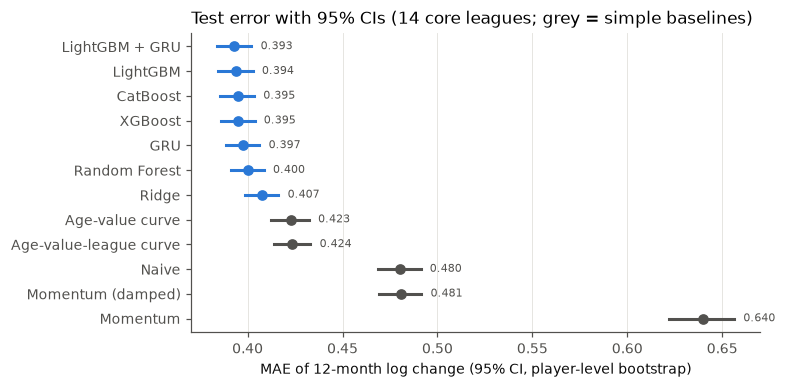

In [4]:
order = model_ci.index[::-1]
fig, ax = plt.subplots(figsize=(7.2, 3.6))
for k, m in enumerate(order):
    j = names.index(m)
    lo, hi = ci(boot_mae[:, j])
    color = TEXT_SECONDARY if m in SIMPLE else PALETTE[0]
    ax.plot([lo, hi], [k, k], color=color, linewidth=2)
    ax.plot(E[m].mean(), k, "o", color=color, markersize=6)
    ax.annotate(f"{E[m].mean():.3f}", (hi, k), xytext=(6, 0), textcoords="offset points",
                va="center", fontsize=7, color=TEXT_SECONDARY)
ax.set_yticks(range(len(order)), order)
ax.set_xlabel("MAE of 12-month log change (95% CI, player-level bootstrap)")
ax.grid(axis="x", color=GRID, linewidth=0.6)
ax.grid(axis="y", visible=False)
ax.set_title("Test error with 95% CIs (14 core leagues; grey = simple baselines)", loc="left")
fig.tight_layout()
savefig(fig, "fig06_model_mae_ci")
plt.show()

### 1b. Paired differences between models

For each pair (A, B) we bootstrap **MAE(A) − MAE(B)** on the same resampled players. A negative difference means A is better.

In [5]:
top = ["LightGBM", "CatBoost", "XGBoost", "GRU", "LightGBM + GRU"]
pairs = [(a, b) for i, a in enumerate(top) for b in top[i + 1:]]
pairs += [("LightGBM", "Random Forest"), ("LightGBM", "Ridge"), ("Random Forest", "Ridge")]
pairs += [("LightGBM", b) for b in SIMPLE[1:]]
pairs += [(m, "Naive") for m in names if m != "Naive"]
rows = []
for a, b in pairs:
    ia, ib = names.index(a), names.index(b)
    d = boot_mae[:, ia] - boot_mae[:, ib]
    lo, hi = ci(d)
    rows.append({"A": a, "B": b, "MAE(A) − MAE(B)": E[a].mean() - E[b].mean(),
                 "95% CI low": lo, "95% CI high": hi, "verdict": verdict(lo, hi, a, b)})
paired = pd.DataFrame(rows).round({"MAE(A) − MAE(B)": 4, "95% CI low": 4, "95% CI high": 4})
paired.to_csv(RESULTS / "table17_bootstrap_paired_differences.csv", index=False)
paired

,A,B,MAE(A) − MAE(B),95% CI low,95% CI high,verdict
0,LightGBM,CatBoost,-0.0008,-0.0018,0.0002,no clear difference
1,LightGBM,XGBoost,-0.0010,-0.0022,0.0002,no clear difference
2,LightGBM,GRU,-0.0033,-0.0053,-0.0013,LightGBM better
3,LightGBM,LightGBM + GRU,0.0009,-0.0001,0.0020,no clear difference
4,CatBoost,XGBoost,-0.0002,-0.0015,0.0012,no clear difference
5,CatBoost,GRU,-0.0025,-0.0044,-0.0004,CatBoost better
6,CatBoost,LightGBM + GRU,0.0018,0.0005,0.0031,LightGBM + GRU better
7,XGBoost,GRU,-0.0023,-0.0044,-0.0001,XGBoost better
8,XGBoost,LightGBM + GRU,0.0019,0.0005,0.0034,LightGBM + GRU better
9,GRU,LightGBM + GRU,0.0042,0.0032,0.0052,LightGBM + GRU better


### 1b-2. Every model vs. the best simple baseline

This is the paired bootstrap of MAE(model) − MAE(best simple baseline), together with the skill vs. that baseline. Negative differences mean the model is better.

In [6]:
bi = names.index(BEST)
rows = []
for j, m in enumerate(names):
    if m == BEST:
        continue
    d = boot_mae[:, j] - boot_mae[:, bi]
    s = 100 * (1 - boot_mae[:, j] / boot_mae[:, bi])
    lo, hi = ci(d)
    rows.append({"model": m, "MAE(model) − MAE(best simple)": E[m].mean() - E[BEST].mean(),
                 "95% CI low": lo, "95% CI high": hi, "verdict": verdict(lo, hi, m, BEST),
                 "skill vs best simple %": 100 * (1 - E[m].mean() / E[BEST].mean()),
                 "skill 95% CI": "[{:.1f}, {:.1f}]".format(*ci(s))})
vs_best = pd.DataFrame(rows).set_index("model").round({"MAE(model) − MAE(best simple)": 4, "95% CI low": 4,
                                                       "95% CI high": 4, "skill vs best simple %": 1})
vs_best.to_csv(RESULTS / "table17b_vs_best_simple_baseline.csv")
print("best simple baseline:", BEST)
vs_best

best simple baseline: Age-value curve


,MAE(model) − MAE(best simple),95% CI low,95% CI high,verdict,skill vs best simple %,skill 95% CI
model,,,,,,
Naive,0.0574,0.0517,0.0632,Age-value curve better,-13.6,"[-15.0, -12.2]"
Age-value-league curve,0.0010,-0.0010,0.0029,no clear difference,-0.2,"[-0.7, 0.2]"
Momentum,0.2173,0.2034,0.2309,Age-value curve better,-51.4,"[-55.0, -47.9]"
Momentum (damped),0.0582,0.0505,0.0654,Age-value curve better,-13.8,"[-15.6, -11.8]"
Ridge,-0.0152,-0.0186,-0.0117,Ridge better,3.6,"[2.8, 4.3]"
Random Forest,-0.0225,-0.0264,-0.0184,Random Forest better,5.3,"[4.4, 6.2]"
XGBoost,-0.0276,-0.0315,-0.0237,XGBoost better,6.5,"[5.7, 7.4]"
CatBoost,-0.0278,-0.0316,-0.0242,CatBoost better,6.6,"[5.7, 7.4]"
LightGBM,-0.0286,-0.0322,-0.0250,LightGBM better,6.8,"[6.0, 7.6]"


### 1c. The three splits, with confidence intervals

- Each scheme has its **own** test rows, so the schemes cannot be compared pair-wise on the same players.
- We bootstrap each scheme separately, by player, and compare the **skill vs. naive**. Skill is measured on the same rows as that scheme's naive baseline, so it adjusts for how hard each test set is.
- The difference between two schemes is taken across independent bootstrap draws.

In [7]:
sp = pd.read_parquet(PROCESSED / "predictions_split_comparison.parquet")
sp["err_model"] = (sp.pred_LightGBM - sp.y).abs()
sp["err_naive"] = (sp.log_value - sp.y).abs()
skill_draws, rows = {}, []
for k, (scheme, d) in enumerate(sp.groupby("scheme", sort=False)):
    for subset, dd in [("all test rows", d), ("t ≥ 2024-07", d[d.t >= VAL_END])]:
        if scheme == "Time split" and subset != "all test rows":
            continue
        b = cluster_bootstrap_means(dd.player_id, dd[["err_model", "err_naive"]], seed=SEED + k)
        s = 100 * (1 - b[:, 0] / b[:, 1])
        skill_draws[(scheme, subset)] = s
        point = 100 * (1 - dd.err_model.mean() / dd.err_naive.mean())
        rows.append({"scheme": scheme, "test rows": subset, "n": len(dd), "players": dd.player_id.nunique(),
                     "MAE_change": round(dd.err_model.mean(), 4), "skill_vs_naive_%": round(point, 1),
                     "skill 95% CI": "[{:.1f}, {:.1f}]".format(*ci(s))})
split_ci = pd.DataFrame(rows).set_index(["scheme", "test rows"])
display(split_ci)

comparisons = [(("Random 80/20 (rows)", "all test rows"), ("Time split", "all test rows")),
               (("Random 80/20 (by player)", "all test rows"), ("Time split", "all test rows")),
               (("Random 80/20 (rows)", "all test rows"), ("Random 80/20 (by player)", "all test rows")),
               (("Random 80/20 (rows)", "t ≥ 2024-07"), ("Time split", "all test rows")),
               (("Random 80/20 (by player)", "t ≥ 2024-07"), ("Time split", "all test rows")),
               (("Random 80/20 (rows)", "t ≥ 2024-07"), ("Random 80/20 (by player)", "t ≥ 2024-07"))]
rows = []
for a, b in comparisons:
    d = skill_draws[a] - skill_draws[b]
    lo, hi = ci(d)
    rows.append({"A": f"{a[0]} [{a[1]}]", "B": f"{b[0]} [{b[1]}]",
                 "skill(A) − skill(B), points": round(split_ci.loc[a, "skill_vs_naive_%"] - split_ci.loc[b, "skill_vs_naive_%"], 1),
                 "95% CI": f"[{lo:.1f}, {hi:.1f}]",
                 "verdict": "no clear difference" if lo <= 0 <= hi else ("A higher" if lo > 0 else "B higher")})
split_diff = pd.DataFrame(rows)
split_ci.to_csv(RESULTS / "table18_split_comparison_ci.csv")
split_diff.to_csv(RESULTS / "table18b_split_comparison_differences.csv", index=False)
split_diff

n  players  MAE_change  skill_vs_naive_%  skill 95% CI
scheme                   test rows                                                                
Time split               all test rows  12167     6292      0.3981              17.1  [15.7, 18.5]
Random 80/20 (rows)      all test rows  27266    12636      0.3594              19.7  [18.9, 20.5]
                         t ≥ 2024-07     2472     2197      0.3722              23.8  [21.3, 26.1]
Random 80/20 (by player) all test rows  27268     4058      0.3733              17.5  [16.4, 18.5]
                         t ≥ 2024-07     2512     1287      0.4030              19.7  [16.7, 22.6]

,A,B,"skill(A) − skill(B), points",95% CI,verdict
0,Random 80/20 (rows) [all test rows],Time split [all test rows],2.6,"[1.0, 4.3]",A higher
1,Random 80/20 (by player) [all test rows],Time split [all test rows],0.4,"[-1.2, 2.0]",no clear difference
2,Random 80/20 (rows) [all test rows],Random 80/20 (by player) [all test rows],2.2,"[1.0, 3.4]",A higher
3,Random 80/20 (rows) [t ≥ 2024-07],Time split [all test rows],6.7,"[3.8, 9.5]",A higher
4,Random 80/20 (by player) [t ≥ 2024-07],Time split [all test rows],2.6,"[-0.6, 5.8]",no clear difference
5,Random 80/20 (rows) [t ≥ 2024-07],Random 80/20 (by player) [t ≥ 2024-07],4.1,"[0.4, 7.8]",A higher


## 2. Where is the gain over the naive baseline largest?

We compare **LightGBM vs. naive** inside each group. For each group:
- **skill** = 1 − MAE(LightGBM) / MAE(naive), with a 95% player-level bootstrap interval;
- % within ±20% for both models.

The MAE of *every* model in every group is saved in `table20_mae_by_group_all_models.csv`.

Groups (bins fixed in `src/config.py` before looking at results):
- **age** at *t*: <21, 21–25, 26–29, 30+
- **position**
- **value level** at *t*: cheap (<€1m), medium (€1–10m), expensive (≥€10m)
- **size of the real 12-month change**: this uses the outcome, so it is descriptive only. It shows which kinds of moves the model captures.
  - Skill (a ratio) is not meaningful here: for players whose value did not change, the naive error is about 0.
  - So this panel shows the **MAE of both models side by side** instead.
- **league**: the 14 core leagues (in training) and the 17 new leagues (not in training; separate test set)

**Two references.** Each group gets two skill values with paired player-level bootstrap intervals:
- skill vs. the **naive** forecast;
- skill vs. the **best simple baseline**, the age × value curve.

The second one already "knows" the typical development by age and value level, so it shows whether the gain in a group is more than the usual age pattern.

In [8]:
newl = preds[preds.test_set == "new_leagues"].reset_index(drop=True)
both = pd.concat([core, newl], ignore_index=True)
both["age group"] = pd.cut(both.age, AGE_BINS, labels=AGE_LABELS, right=False)
both["value level"] = pd.cut(both.value_t, VALUE_BINS, labels=VALUE_LABELS, right=False)
chg = both.y - both.log_value
CHG_EDGES = [-np.inf, np.log(0.67), np.log(0.9), np.log(1.1), np.log(1.5), np.inf]
CHG_LABELS = ["fell >33%", "fell 10–33%", "within about ±10%", "rose 10–50%", "rose >50%"]
both["real change"] = pd.cut(chg, CHG_EDGES, labels=CHG_LABELS)
both["league"] = both.league_t.astype(str)
E_both, W_both = abs_errors(both), within20(both)

def group_table(var, d_mask=None):
    rows = []
    d_all = both if d_mask is None else both[d_mask]
    for g, d in d_all.groupby(var, observed=True, sort=True):
        e = E_both.loc[d.index, ["LightGBM", "Naive", BEST]]
        b = cluster_bootstrap_means(d.player_id, e)
        sb = 100 * (1 - b[:, 0] / b[:, 2])
        s = 100 * (1 - b[:, 0] / b[:, 1])
        lo, hi = ci(s)
        glo, ghi = ci(b[:, 1] - b[:, 0])
        rows.append({"grouping": var, "group": str(g), "n": len(d), "players": d.player_id.nunique(),
                     "MAE naive": e["Naive"].mean(), "MAE LightGBM": e["LightGBM"].mean(),
                     "gain (MAE naive − MAE LightGBM)": e["Naive"].mean() - e["LightGBM"].mean(),
                     "gain_lo": glo, "gain_hi": ghi,
                     "MAE naive lo": ci(b[:, 1])[0], "MAE naive hi": ci(b[:, 1])[1],
                     "MAE LightGBM lo": ci(b[:, 0])[0], "MAE LightGBM hi": ci(b[:, 0])[1],
                     "skill_%": 100 * (1 - e["LightGBM"].mean() / e["Naive"].mean()), "skill_lo": lo, "skill_hi": hi,
                     "within20 naive %": 100 * W_both.loc[d.index, "Naive"].mean(),
                     "within20 LightGBM %": 100 * W_both.loc[d.index, "LightGBM"].mean(),
                     # added: the same comparison against the best simple baseline (age x value curve)
                     "MAE best simple": e[BEST].mean(), "MAE best simple lo": ci(b[:, 2])[0], "MAE best simple hi": ci(b[:, 2])[1],
                     "skill_vs_best_%": 100 * (1 - e["LightGBM"].mean() / e[BEST].mean()),
                     "skill_vs_best_lo": ci(sb)[0], "skill_vs_best_hi": ci(sb)[1],
                     "within20 best simple %": 100 * W_both.loc[d.index, BEST].mean()})
    return pd.DataFrame(rows)

is_core = (both.test_set == "core").to_numpy()
groups = pd.concat([group_table("age group", is_core), group_table("position", is_core),
                    group_table("value level", is_core), group_table("real change", is_core)], ignore_index=True)
leagues = group_table("league")
leagues["set"] = np.where(leagues.group.isin(core.league_t.astype(str).unique()), "core (in training)", "new (not in training)")
by_group = pd.concat([groups.assign(set="core test"), leagues], ignore_index=True).round(3)
by_group.to_csv(RESULTS / "table19_error_by_group.csv", index=False)

allm = []
for var in ["age group", "position", "value level", "real change", "league"]:
    m = E_both.groupby(both[var], observed=True).mean()
    if var != "league":
        m = E_both[is_core].groupby(both.loc[is_core, var], observed=True).mean()
    allm.append(m.assign(grouping=var).rename_axis("group").reset_index())
pd.concat(allm, ignore_index=True).round(4).to_csv(RESULTS / "table20_mae_by_group_all_models.csv", index=False)
groups[["grouping", "group", "n", "skill_%", "skill_lo", "skill_hi", "skill_vs_best_%", "skill_vs_best_lo",
        "skill_vs_best_hi", "MAE naive", "MAE best simple", "MAE LightGBM"]].round(3)

,grouping,group,n,skill_%,skill_lo,skill_hi,skill_vs_best_%,skill_vs_best_lo,skill_vs_best_hi,MAE naive,MAE best simple,MAE LightGBM
0,age group,<21,1686,17.150,14.565,19.789,9.278,7.138,11.548,0.781,0.713,0.647
1,age group,21–25,5038,6.582,5.221,7.908,6.570,5.487,7.699,0.448,0.448,0.419
2,age group,26–29,3174,15.068,13.109,17.199,6.279,4.724,7.807,0.367,0.333,0.312
3,age group,30+,2269,45.133,43.141,46.845,3.520,1.367,5.816,0.485,0.276,0.266
4,position,Attack,3286,16.664,14.749,18.798,6.353,4.709,8.011,0.506,0.450,0.422
5,position,Defender,4081,19.063,17.263,20.987,7.003,5.528,8.408,0.457,0.398,0.370
6,position,Goalkeeper,1259,11.224,7.925,14.445,5.770,2.792,8.765,0.428,0.403,0.380
7,position,Midfield,3541,19.921,18.149,21.633,7.266,5.680,8.698,0.501,0.432,0.401
8,value level,cheap (<€1m),4127,14.586,12.612,16.439,5.373,3.959,6.775,0.529,0.477,0.451
9,value level,medium (€1–10m),5549,19.880,18.437,21.464,7.877,6.617,9.050,0.492,0.428,0.394


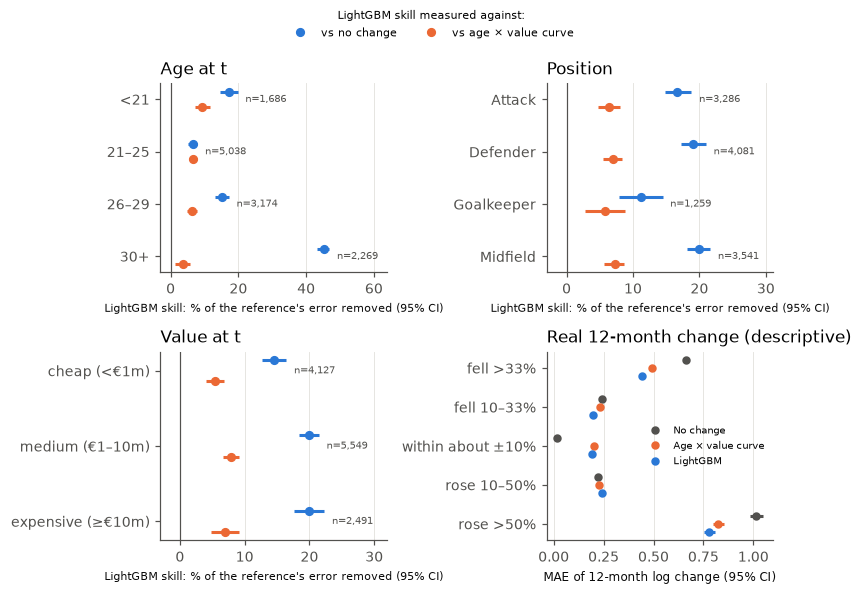

In [9]:
panels = ["age group", "position", "value level", "real change"]
titles = {"age group": "Age at t", "position": "Position", "value level": "Value at t",
          "real change": "Real 12-month change (descriptive)"}
SER = [("skill", "vs no change", PALETTE[0], 0.14), ("skill_vs_best", "vs age × value curve", PALETTE[1], -0.14)]
fig, axes = plt.subplots(2, 2, figsize=(7.2, 5.4))
for ax, var in zip(axes.flat, panels):
    d = groups[groups.grouping == var].reset_index(drop=True)
    y = np.arange(len(d))[::-1]
    if var == "real change":
        for off, (col, color, label) in zip([0.2, 0.0, -0.2], [("MAE naive", TEXT_SECONDARY, "No change"),
                                                               ("MAE best simple", PALETTE[1], "Age × value curve"),
                                                               ("MAE LightGBM", PALETTE[0], "LightGBM")]):
            ax.hlines(y + off, d[f"{col} lo"], d[f"{col} hi"], color=color, linewidth=2)
            ax.plot(d[col], y + off, "o", color=color, markersize=4.5, label=label)
        ax.set_yticks(y, d.group)
        ax.set_title(titles[var], loc="left")
        ax.set_xlabel("MAE of 12-month log change (95% CI)", fontsize=8)
        ax.legend(loc="center right", fontsize=6.5)
        ax.grid(axis="x", color=GRID, linewidth=0.6)
        ax.grid(axis="y", visible=False)
        continue
    for key, label, color, off in SER:
        col = "skill_%" if key == "skill" else "skill_vs_best_%"
        ax.hlines(y + off, d[f"{key}_lo"], d[f"{key}_hi"], color=color, linewidth=2)
        ax.plot(d[col], y + off, "o", color=color, markersize=5, label=label)
    for yi, (_, r) in zip(y, d.iterrows()):
        ax.annotate(f"n={r.n:,}", (max(r.skill_hi, r.skill_vs_best_hi), yi), xytext=(5, 0),
                    textcoords="offset points", va="center", fontsize=6.5, color=TEXT_SECONDARY)
    ax.axvline(0, color=TEXT_SECONDARY, linewidth=0.8)
    ax.set_yticks(y, d.group)
    ax.set_title(titles[var], loc="left")
    ax.grid(axis="x", color=GRID, linewidth=0.6)
    ax.grid(axis="y", visible=False)
    lo = min(d.skill_lo.min(), d.skill_vs_best_lo.min(), 0)
    hi = max(d.skill_hi.max(), d.skill_vs_best_hi.max())
    ax.set_xlim(lo - 3, hi + 0.3 * (hi - lo + 10))
    ax.set_xlabel("LightGBM skill: % of the reference's error removed (95% CI)", fontsize=7.5)
h, l = axes[0][0].get_legend_handles_labels()
fig.legend(h, l, loc="upper center", ncols=2, fontsize=7.5, frameon=False, title="LightGBM skill measured against:",
           title_fontsize=7.5)
fig.tight_layout(rect=(0, 0, 1, 0.93))
savefig(fig, "fig07_gain_by_group")
plt.show()

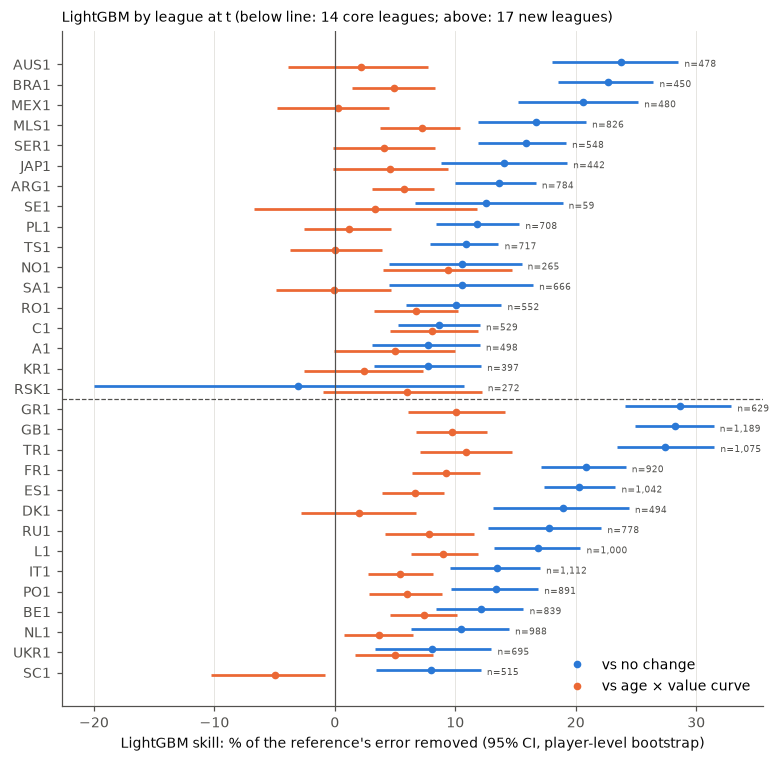

,grouping,group,n,players,MAE naive,MAE LightGBM,gain (MAE naive − MAE LightGBM),gain_lo,gain_hi,MAE naive lo,MAE naive hi,MAE LightGBM lo,MAE LightGBM hi,skill_%,skill_lo,skill_hi,within20 naive %,within20 LightGBM %,MAE best simple,MAE best simple lo,MAE best simple hi,skill_vs_best_%,skill_vs_best_lo,skill_vs_best_hi,within20 best simple %,set
10,league,GR1,629,373,0.4,0.3,0.1,0.1,0.1,0.3,0.4,0.2,0.3,28.7,24.1,32.9,41.2,53.7,0.3,0.3,0.3,10.1,6.1,14.1,50.4,core (in training)
9,league,GB1,1189,589,0.5,0.3,0.1,0.1,0.2,0.4,0.5,0.3,0.4,28.2,24.9,31.4,29.8,41.0,0.4,0.3,0.4,9.7,6.8,12.6,37.4,core (in training)
28,league,TR1,1075,473,0.5,0.3,0.1,0.1,0.2,0.4,0.5,0.3,0.4,27.4,23.4,31.5,27.3,41.5,0.4,0.4,0.4,10.9,7.0,14.7,35.3,core (in training)
2,league,AUS1,478,249,0.4,0.3,0.1,0.1,0.1,0.4,0.5,0.3,0.4,23.7,18.1,28.5,35.8,45.4,0.3,0.3,0.4,2.2,-3.9,7.7,46.7,new (not in training)
4,league,BRA1,450,449,0.5,0.4,0.1,0.1,0.1,0.4,0.5,0.3,0.4,22.6,18.5,26.4,30.0,41.3,0.4,0.3,0.4,4.9,1.4,8.3,43.3,new (not in training)
8,league,FR1,920,486,0.6,0.5,0.1,0.1,0.2,0.6,0.7,0.4,0.5,20.8,17.1,24.1,25.7,35.4,0.5,0.5,0.6,9.3,6.4,12.1,32.7,core (in training)
15,league,MEX1,480,360,0.4,0.3,0.1,0.1,0.1,0.4,0.4,0.3,0.4,20.6,15.2,25.2,32.1,47.7,0.3,0.3,0.4,0.3,-4.8,4.5,52.7,new (not in training)
7,league,ES1,1042,542,0.5,0.4,0.1,0.1,0.1,0.5,0.6,0.4,0.5,20.3,17.3,23.3,29.5,39.8,0.4,0.4,0.5,6.6,3.9,9.1,37.4,core (in training)
6,league,DK1,494,308,0.5,0.4,0.1,0.1,0.1,0.5,0.6,0.4,0.4,18.9,13.2,24.4,34.8,34.4,0.4,0.4,0.5,2.0,-2.8,6.7,34.2,core (in training)
23,league,RU1,778,417,0.4,0.3,0.1,0.0,0.1,0.4,0.4,0.3,0.4,17.8,12.7,22.1,37.3,40.2,0.4,0.3,0.4,7.8,4.2,11.5,39.3,core (in training)


In [10]:
L = leagues.sort_values(["set", "skill_%"], ascending=[True, True]).reset_index(drop=True)
fig, ax = plt.subplots(figsize=(7.2, 7.0))
y = np.arange(len(L))
for key, label, color, off in SER:
    col = "skill_%" if key == "skill" else "skill_vs_best_%"
    ax.hlines(y + off, L[f"{key}_lo"], L[f"{key}_hi"], color=color, linewidth=1.8)
    ax.plot(L[col], y + off, "o", color=color, markersize=4, label=label)
for yi, (_, r) in zip(y, L.iterrows()):
    ax.annotate(f"n={r.n:,}", (max(r.skill_hi, r.skill_vs_best_hi), yi), xytext=(4, 0), textcoords="offset points",
                va="center", fontsize=6, color=TEXT_SECONDARY)
split_at = (L.set == "new (not in training)").to_numpy().argmax() - 0.5
ax.axhline(split_at, color=TEXT_SECONDARY, linewidth=0.8, linestyle="--")
ax.axvline(0, color=TEXT_SECONDARY, linewidth=0.8)
ax.set_yticks(y, L.group)
ax.set_xlabel("LightGBM skill: % of the reference's error removed (95% CI, player-level bootstrap)")
ax.set_title("LightGBM by league at t (below line: 14 core leagues; above: 17 new leagues)", loc="left", fontsize=9)
ax.grid(axis="x", color=GRID, linewidth=0.6)
ax.grid(axis="y", visible=False)
ax.legend(loc="lower right")
fig.tight_layout()
savefig(fig, "fig08_gain_by_league")
plt.show()
leagues.sort_values("skill_%", ascending=False).round(1)

## 3. SHAP explanations (LightGBM)

- **What is explained:** the model's predicted **12-month log change**. A positive SHAP value means the feature pushes the forecast towards a **rise**; a negative value pushes it towards a **fall**.
- **Method:** exact TreeSHAP values from LightGBM itself (`pred_contrib=True`). This handles the categorical features (league, position, …) directly.
- **Sample:** 3,000 core test rows drawn at random with the fixed seed.

In [11]:
full = load_dataset()
main, _ = main_and_extra(full)
test_df = main[main.split == "test"].reset_index(drop=True)
assert (test_df.player_id.to_numpy() == core.player_id.to_numpy()).all() and (test_df.t.to_numpy() == core.t.to_numpy()).all()

booster = lgb.Booster(model_file=str(ROOT / "models" / "lightgbm.txt"))
sample = test_df.sample(3000, random_state=SEED)
X = sample[FEATURES]
contrib = booster.predict(X, pred_contrib=True)
sv, base = contrib[:, :-1], contrib[:, -1]
pred_chg = booster.predict(X)
print("SHAP values add up to the prediction:", np.allclose(sv.sum(1) + base, pred_chg, atol=1e-6))
print("Loaded model reproduces notebook-03 predictions:",
      np.allclose(sample.log_value.to_numpy() + pred_chg, core.loc[sample.index, "pred_LightGBM"].to_numpy(), atol=1e-6))
print(f"Average predicted log change (base value): {base[0]:.4f}")

SHAP values add up to the prediction: True
Loaded model reproduces notebook-03 predictions: True
Average predicted log change (base value): -0.0493


In [12]:
num = [f for f in FEATURES if f not in CATEGORICAL]
imp = pd.DataFrame({"feature": FEATURES, "group": [FEATURE_INFO[f][0] for f in FEATURES],
                    "mean_abs_SHAP": np.abs(sv).mean(0)})
direction = {}
for j, f in enumerate(FEATURES):
    if f in num:
        x = X[f].astype(float)
        ok = x.notna().to_numpy()
        if x[ok].nunique() <= 1:
            direction[f] = "constant in this sample (no effect)"
            continue
        r = pd.Series(x[ok].to_numpy()).corr(pd.Series(sv[ok, j]), method="spearman")
        direction[f] = ("higher value → higher forecast" if r > 0.1 else "higher value → lower forecast" if r < -0.1
                        else "mixed / non-monotone") + f" (ρ={r:.2f})"
    else:
        direction[f] = "categorical (see per-category table)"
imp["direction"] = imp.feature.map(direction)
imp["description"] = imp.feature.map(lambda f: FEATURE_INFO[f][1])
imp = imp.sort_values("mean_abs_SHAP", ascending=False).reset_index(drop=True)
imp["rank"] = imp.index + 1
imp.round(4).to_csv(RESULTS / "table21_shap_importance.csv", index=False)

grp = (imp.groupby("group")["mean_abs_SHAP"].sum().sort_values(ascending=False)
          .rename("sum of mean |SHAP|").to_frame())
grp["share_%"] = 100 * grp.iloc[:, 0] / grp.iloc[:, 0].sum()
grp.round(4).to_csv(RESULTS / "table22_shap_group_importance.csv")
display(grp.round(3))
imp.head(15)[["rank", "feature", "group", "mean_abs_SHAP", "direction"]].round(4)

,sum of mean |SHAP|,share_%
group,,
value history,0.234,32.234
club/league,0.198,27.254
player,0.125,17.261
performance,0.095,13.162
transfers,0.073,10.090


,rank,feature,group,mean_abs_SHAP,direction
0,1,age,player,0.1039,higher value → lower forecast (ρ=-0.98)
1,2,change_since_prev_valuation,value history,0.0524,higher value → higher forecast (ρ=0.92)
2,3,value_vs_league_median,club/league,0.0399,higher value → lower forecast (ρ=-0.95)
3,4,n_valuations_so_far,value history,0.0348,higher value → lower forecast (ρ=-0.98)
4,5,days_since_last_appearance,performance,0.0335,higher value → lower forecast (ρ=-0.89)
5,6,value_vs_club_mean,club/league,0.0311,higher value → lower forecast (ρ=-0.95)
6,7,log_value,value history,0.0304,higher value → lower forecast (ρ=-0.94)
7,8,growth_6m,value history,0.0287,higher value → higher forecast (ρ=0.92)
8,9,league_t,club/league,0.0286,categorical (see per-category table)
9,10,club_gd_per_game_365,club/league,0.0282,higher value → higher forecast (ρ=0.95)


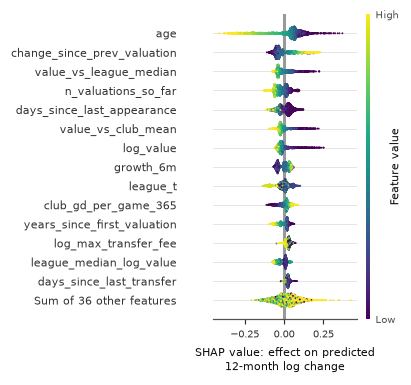

In [13]:
expl = shap.Explanation(values=sv, base_values=base,
                        data=X.apply(lambda c: c.cat.codes.where(c.notna(), np.nan) if c.name in CATEGORICAL
                                     else c.astype(float)).to_numpy(dtype=float),
                        feature_names=FEATURES)
# Sized for one IEEE column (3.5 in wide) so that the text stays readable (about 7 pt) in the paper.
plt.figure()
shap.plots.beeswarm(expl, max_display=15, show=False, color=plt.get_cmap("viridis"),
                    plot_size=(2.12, 3.6), s=1.5)
fig = plt.gcf()
ax, cax = fig.axes[0], fig.axes[1]
ax.tick_params(axis="y", labelsize=7)
ax.tick_params(axis="x", labelsize=6.5)
ax.set_xlabel("SHAP value: effect on predicted\n12-month log change", fontsize=7.5)
cax.tick_params(labelsize=6.5)
cax.set_ylabel("Feature value", fontsize=7, labelpad=-6)
savefig(fig, "fig09_shap_beeswarm")
plt.show()

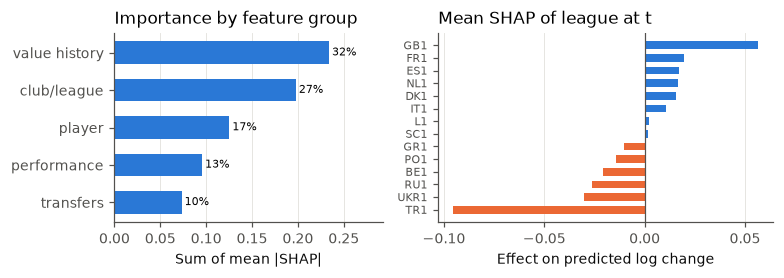

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(7.2, 2.6), gridspec_kw={"width_ratios": [1, 1.25]})
g = grp.iloc[:, 0][::-1]
bars = axes[0].barh(g.index, g.values, color=PALETTE[0], height=0.6)
axes[0].bar_label(bars, labels=[f"{v:.0f}%" for v in grp["share_%"][::-1]], fontsize=7, padding=2)
axes[0].set_title("Importance by feature group", loc="left")
axes[0].set_xlabel("Sum of mean |SHAP|")
axes[0].set_xlim(0, g.max() * 1.25)
cat_imp = imp[imp.feature.isin(CATEGORICAL)]
league_j = FEATURES.index("league_t")
lg = pd.DataFrame({"league": X["league_t"].astype(str).to_numpy(), "shap": sv[:, league_j]})
lg = lg.groupby("league")["shap"].agg(["mean", "size"]).sort_values("mean")
axes[1].barh(lg.index, lg["mean"], color=[PALETTE[1] if v < 0 else PALETTE[0] for v in lg["mean"]], height=0.6)
axes[1].axvline(0, color=TEXT_SECONDARY, linewidth=0.8)
axes[1].set_title("Mean SHAP of league at t", loc="left")
axes[1].xaxis.set_major_locator(plt.MaxNLocator(4))
axes[1].set_xlabel("Effect on predicted log change")
axes[1].tick_params(axis="y", labelsize=7)
for ax in axes:
    ax.grid(axis="y", visible=False)
    ax.grid(axis="x", color=GRID, linewidth=0.6)
fig.tight_layout()
savefig(fig, "fig10_shap_groups_and_league")
plt.show()
lg.round(4).to_csv(RESULTS / "table22b_shap_league_effect.csv")

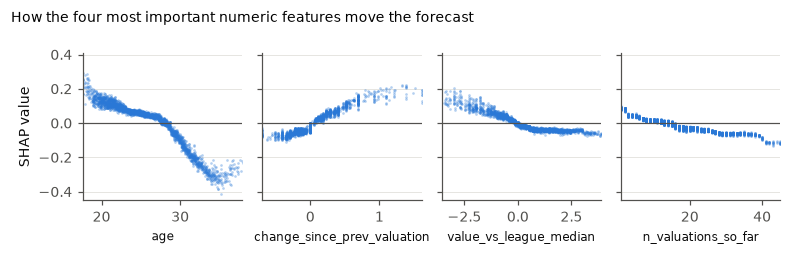

In [15]:
top_num = [f for f in imp.feature if f in num][:4]
fig, axes = plt.subplots(1, 4, figsize=(7.2, 2.3), sharey=True)
for ax, f in zip(axes, top_num):
    j = FEATURES.index(f)
    x = X[f].astype(float).to_numpy()
    ax.scatter(x, sv[:, j], s=3, alpha=0.35, color=PALETTE[0], linewidths=0)
    ax.axhline(0, color=TEXT_SECONDARY, linewidth=0.8)
    ax.set_xlabel(f, fontsize=8)
    lo, hi = np.nanquantile(x, [0.005, 0.995])
    ax.set_xlim(lo, hi)
axes[0].set_ylabel("SHAP value")
fig.suptitle("How the four most important numeric features move the forecast", x=0.01, ha="left", fontsize=9)
fig.tight_layout()
savefig(fig, "fig11_shap_dependence")
plt.show()

## 4. "Undervalued" check

- **Definition:** a player is *"undervalued"* at *t* if LightGBM predicts one of the **10% largest rises** among all core test rows. In other words, the model expects the market value to go up much more than for other players. *"Overvalued"* = the 10% largest predicted falls.
- **Two outcomes after *t*:**
  1. Did the market value really rise over 12 months? (the target)
  2. From `transfers.csv`: was the player **sold for a fee within 12 months** after *t*, and was that fee **above** the market value at *t*?
- **Simple rule for comparison:** the **youngest 10%** of players. Young players tend to rise, so this checks that the model does more than pick young players.
- Transfers after *t* are used **only as an outcome** here, never as model input.

In [16]:
tr = pd.read_parquet(PROCESSED / "transfers.parquet", columns=["player_id", "transfer_date", "transfer_fee"])
last_real = tr.loc[tr.transfer_date <= "2026-10-17", "transfer_date"].max()
paid = tr[(tr.transfer_fee > 0) & (tr.transfer_date <= last_real)]
u = core[["player_id", "t", "value_t", "y", "log_value", "pred_LightGBM", "age"]].copy()
u["pred_chg"] = u.pred_LightGBM - u.log_value
u["real_chg"] = u.y - u.log_value
k = int(np.ceil(0.10 * len(u)))
u["group"] = "middle 80%"
u.loc[u.pred_chg.nlargest(k).index, "group"] = "undervalued (top 10% predicted rise)"
u.loc[u.pred_chg.nsmallest(k).index, "group"] = "overvalued (top 10% predicted fall)"
youngest = u.age.nsmallest(k).index

m = u[["player_id", "t", "value_t"]].reset_index().merge(paid, on="player_id")
m = m[(m.transfer_date > m.t) & (m.transfer_date <= m.t + pd.Timedelta(days=365))]
first = m.sort_values("transfer_date").drop_duplicates("index").set_index("index")
u["sold_for_fee_12m"] = u.index.isin(first.index).astype(float)
u["fee_over_value_t"] = (first.transfer_fee / first.value_t).reindex(u.index)
u["window_complete"] = (u.t + pd.Timedelta(days=365) <= last_real)
print(f"last recorded transfer date: {last_real.date()} | rows whose 12-month window is fully observed: {u.window_complete.mean():.1%}")

def outcome(d, name):
    b = cluster_bootstrap_means(d.player_id, pd.DataFrame({"rose": (d.real_chg > 0).astype(float),
                                                          "sold": d.sold_for_fee_12m}))
    sold = d[d.sold_for_fee_12m == 1]
    return {"group": name, "rows": len(d), "players": d.player_id.nunique(),
            "median predicted change %": 100 * np.expm1(d.pred_chg.median()),
            "median real change %": 100 * np.expm1(d.real_chg.median()),
            "really rose %": 100 * (d.real_chg > 0).mean(), "rose 95% CI": "[{:.1f}, {:.1f}]".format(*(100 * np.array(ci(b[:, 0])))),
            "really fell %": 100 * (d.real_chg < 0).mean(),
            "sold for a fee within 12m %": 100 * d.sold_for_fee_12m.mean(),
            "sold 95% CI": "[{:.1f}, {:.1f}]".format(*(100 * np.array(ci(b[:, 1])))),
            "median fee / value at t (sold)": sold.fee_over_value_t.median(),
            "fee > value at t (% of sold)": 100 * (sold.fee_over_value_t > 1).mean(),
            "median age": d.age.median(), "median value at t (€m)": d.value_t.median() / 1e6}

uv = pd.DataFrame([outcome(u[u.group == g], g) for g in
                   ["undervalued (top 10% predicted rise)", "middle 80%", "overvalued (top 10% predicted fall)"]]
                  + [outcome(u.loc[youngest], "simple rule: youngest 10%"), outcome(u, "all core test rows")])
uv = uv.set_index("group").round(2)
uv.to_csv(RESULTS / "table23_undervalued_check.csv")
uv

last recorded transfer date: 2026-10-06 | rows whose 12-month window is fully observed: 100.0%


,rows,players,median predicted change %,median real change %,really rose %,rose 95% CI,really fell %,sold for a fee within 12m %,sold 95% CI,median fee / value at t (sold),fee > value at t (% of sold),median age,median value at t (€m)
group,,,,,,,,,,,,,
undervalued (top 10% predicted rise),1217,892,73.05,100.00,73.05,"[70.2, 75.8]",12.90,16.43,"[13.9, 19.1]",2.50,70.50,20.270000,0.6
middle 80%,9733,5376,-5.46,-6.67,34.95,"[33.7, 36.1]",50.87,18.18,"[17.1, 19.3]",0.87,38.33,25.360001,2.5
overvalued (top 10% predicted fall),1217,753,-38.45,-40.00,1.64,"[0.9, 2.4]",95.56,10.76,"[8.5, 13.0]",0.56,15.27,31.900000,3.0
simple rule: youngest 10%,1217,730,49.56,54.76,65.82,"[62.8, 69.2]",19.88,17.34,"[14.2, 20.5]",1.67,69.19,19.490000,1.0
all core test rows,12167,6292,-5.46,-8.57,35.43,"[34.3, 36.5]",51.54,17.26,"[16.3, 18.2]",0.88,39.95,25.389999,2.0


### 4b. Ranking vs. simple age rules

Is the model's top-10% ranking better than ranking by age alone? We compare two pairs:
- the 10% largest predicted **rises** vs. the **youngest 10%** of players;
- the 10% largest predicted **falls** vs. the **oldest 10%** of players.

The best simple baseline's own top-10% is shown too. Its predictions take the same value for everyone in one age × value cell, so ties are broken by row order.

Intervals come from the player-level bootstrap. The difference model − rule is paired on the same resampled players.

In [17]:
best_col = MODELS[BEST]
u["best_chg"] = core[best_col] - core["log_value"]
k = int(np.ceil(0.10 * len(u)))
sel = pd.DataFrame(index=u.index)
sel["model_rise"] = u.index.isin(u.pred_chg.sort_values(kind="stable").index[-k:])
sel["best_rise"] = u.index.isin(u.best_chg.sort_values(kind="stable").index[-k:])
sel["youngest"] = u.index.isin(u.age.sort_values(kind="stable").index[:k])
sel["model_fall"] = u.index.isin(u.pred_chg.sort_values(kind="stable").index[:k])
sel["best_fall"] = u.index.isin(u.best_chg.sort_values(kind="stable").index[:k])
sel["oldest"] = u.index.isin(u.age.sort_values(kind="stable").index[-k:])
rose, fell = (u.real_chg > 0).astype(float), (u.real_chg < 0).astype(float)
cols = {}
for c in ["model_rise", "best_rise", "youngest"]:
    cols[c + "_hit"], cols[c] = sel[c] * rose, sel[c].astype(float)
for c in ["model_fall", "best_fall", "oldest"]:
    cols[c + "_hit"], cols[c] = sel[c] * fell, sel[c].astype(float)
cols = pd.DataFrame(cols)
b = cluster_bootstrap_means(u.player_id, cols)
prec = {c: 100 * b[:, list(cols).index(c + "_hit")] / b[:, list(cols).index(c)] for c in sel.columns}
labels = {"model_rise": "LightGBM: top 10% predicted rises", "best_rise": f"{BEST}: top 10% predicted rises",
          "youngest": "Rule: youngest 10%", "model_fall": "LightGBM: top 10% predicted falls",
          "best_fall": f"{BEST}: top 10% predicted falls", "oldest": "Rule: oldest 10%"}
rows = []
for c, rule in [("model_rise", "youngest"), ("best_rise", "youngest"), ("youngest", None),
                ("model_fall", "oldest"), ("best_fall", "oldest"), ("oldest", None)]:
    point = 100 * cols[c + "_hit"].sum() / cols[c].sum()
    row = {"selection": labels[c], "outcome": "really rose %" if c in ("model_rise", "best_rise", "youngest") else "really fell %",
           "precision %": point, "95% CI": "[{:.1f}, {:.1f}]".format(*ci(prec[c]))}
    if rule:
        d = prec[c] - prec[rule]
        lo, hi = ci(d)
        row |= {"minus rule (points)": point - 100 * cols[rule + "_hit"].sum() / cols[rule].sum(),
                "diff 95% CI": f"[{lo:.1f}, {hi:.1f}]",
                "verdict": "no clear difference" if lo <= 0 <= hi else ("better than rule" if lo > 0 else "worse than rule")}
    rows.append(row)
rank_rules = pd.DataFrame(rows).set_index("selection").round({"precision %": 1, "minus rule (points)": 1})
rank_rules.to_csv(RESULTS / "table23b_ranking_vs_age_rules.csv")
rank_rules

,outcome,precision %,95% CI,minus rule (points),diff 95% CI,verdict
selection,,,,,,
LightGBM: top 10% predicted rises,really rose %,73.0,"[70.3, 75.7]",7.2,"[4.2, 10.3]",better than rule
Age-value curve: top 10% predicted rises,really rose %,63.6,"[60.3, 66.8]",-2.2,"[-4.5, 0.1]",no clear difference
Rule: youngest 10%,really rose %,65.8,"[62.5, 69.0]",NaN,NaN,NaN
LightGBM: top 10% predicted falls,really fell %,95.6,"[94.2, 96.7]",6.7,"[4.4, 9.0]",better than rule
Age-value curve: top 10% predicted falls,really fell %,92.6,"[90.7, 94.3]",3.8,"[1.5, 6.1]",better than rule
Rule: oldest 10%,really fell %,88.8,"[86.6, 91.1]",NaN,NaN,NaN


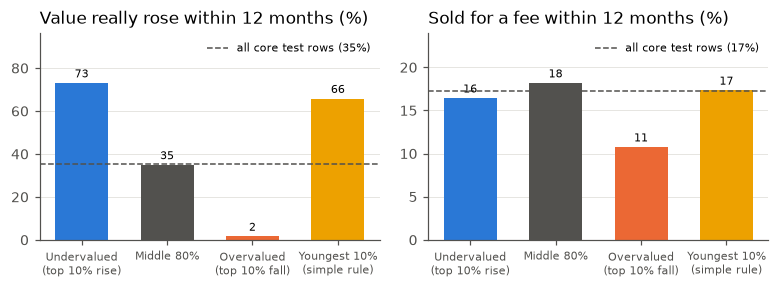

In [18]:
plot = uv.drop(index="all core test rows")
base_r, base_s = uv.loc["all core test rows", ["really rose %", "sold for a fee within 12m %"]]
labels = ["Undervalued\n(top 10% rise)", "Middle 80%", "Overvalued\n(top 10% fall)", "Youngest 10%\n(simple rule)"]
fig, axes = plt.subplots(1, 2, figsize=(7.2, 2.7))
for ax, col, basev, title in [(axes[0], "really rose %", base_r, "Value really rose within 12 months (%)"),
                              (axes[1], "sold for a fee within 12m %", base_s, "Sold for a fee within 12 months (%)")]:
    colors = [PALETTE[0], PALETTE[7], PALETTE[1], PALETTE[3]]
    bars = ax.bar(labels, plot[col], color=colors, width=0.62)
    ax.bar_label(bars, fmt="%.0f", fontsize=7, padding=2)
    ax.axhline(basev, color=TEXT_SECONDARY, linewidth=1, linestyle="--", label=f"all core test rows ({basev:.0f}%)")
    ax.legend(loc="upper right", fontsize=7)
    ax.set_title(title, loc="left")
    ax.tick_params(axis="x", labelsize=7)
    ax.set_ylim(0, max(plot[col].max(), basev) * 1.32)
fig.tight_layout()
savefig(fig, "fig12_undervalued_check")
plt.show()

## Summary

The chat summary for Step 5 lists the key numbers. Every number comes from the tables `table16`–`table23` in `results/` and the figures `fig06`–`fig12`.